# Experiment 6: Fuzzy IF-THEN Rules for Decision Making

**Aim:** To create simple Fuzzy IF-THEN rules for making decisions based on given input conditions.

## Theory
A fuzzy rule has the form: **IF** (x is A) **AND/OR** (y is B) **THEN** (z is C).
* AND → min (or product), OR → max.
* The *firing strength* of a rule is the degree to which its antecedent is true.

Example: *Decide the fan speed of a room from Temperature and Humidity.*

### Step 1: Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
%matplotlib inline

### Step 2: Define input fuzzy sets

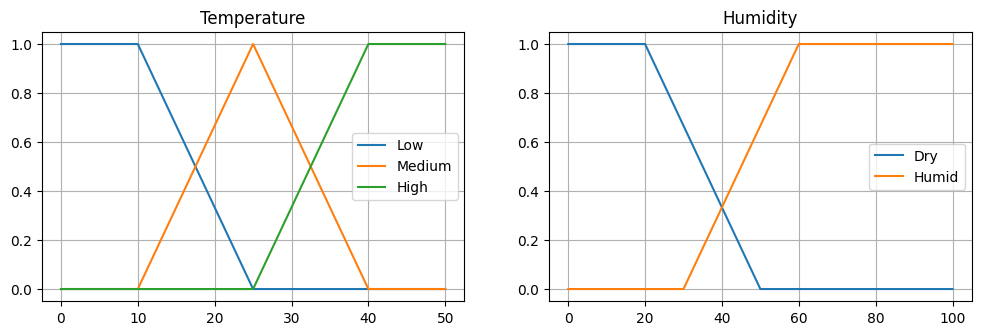

In [2]:
temp = np.arange(0, 51, 1)      # °C
hum  = np.arange(0, 101, 1)     # %

temp_mf = {
    'Low'   : fuzz.trapmf(temp, [0, 0, 10, 25]),
    'Medium': fuzz.trimf(temp,  [10, 25, 40]),
    'High'  : fuzz.trapmf(temp, [25, 40, 50, 50]),
}
hum_mf = {
    'Dry' : fuzz.trapmf(hum, [0, 0, 20, 50]),
    'Humid': fuzz.trapmf(hum, [30, 60, 100, 100]),
}

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for k, v in temp_mf.items(): ax[0].plot(temp, v, label=k)
for k, v in hum_mf.items():  ax[1].plot(hum,  v, label=k)
ax[0].set_title('Temperature'); ax[1].set_title('Humidity')
for a in ax: a.legend(); a.grid(True)
plt.show()

### Step 3: Define the rule base
| # | IF | THEN |
|---|----|------|
| R1 | Temp is Low | Fan = **Off** |
| R2 | Temp is Medium AND Humidity is Dry | Fan = **Slow** |
| R3 | Temp is Medium AND Humidity is Humid | Fan = **Medium** |
| R4 | Temp is High AND Humidity is Dry | Fan = **Medium** |
| R5 | Temp is High AND Humidity is Humid | Fan = **Fast** |

In [3]:
def fire_rules(t, h):
    mt = {k: float(fuzz.interp_membership(temp, v, t)) for k, v in temp_mf.items()}
    mh = {k: float(fuzz.interp_membership(hum,  v, h)) for k, v in hum_mf.items()}
    rules = [
        ("R1: Temp Low                      -> Off   ", mt['Low'],                         'Off'),
        ("R2: Temp Medium AND Dry           -> Slow  ", min(mt['Medium'], mh['Dry']),      'Slow'),
        ("R3: Temp Medium AND Humid         -> Medium", min(mt['Medium'], mh['Humid']),    'Medium'),
        ("R4: Temp High AND Dry             -> Medium", min(mt['High'],   mh['Dry']),      'Medium'),
        ("R5: Temp High AND Humid           -> Fast  ", min(mt['High'],   mh['Humid']),    'Fast'),
    ]
    return rules

### Step 4: Evaluate the rules for a given input

In [4]:
def decide(t, h, verbose=True):
    rules = fire_rules(t, h)
    # aggregate firing strength per output label using max
    out = {}
    for _, strength, label in rules:
        out[label] = max(out.get(label, 0), strength)
    decision = max(out, key=out.get)
    if verbose:
        print(f"Input: Temp = {t} °C, Humidity = {h} %")
        for name, s, _ in rules:
            print(f"  {name}  firing = {s:.2f}")
        print("  Aggregated:", {k: round(v, 2) for k, v in out.items()})
        print(f"  ==> DECISION: Fan speed = {decision}\n")
    return decision

decide(35, 70)

Input: Temp = 35 °C, Humidity = 70 %
  R1: Temp Low                      -> Off     firing = 0.00
  R2: Temp Medium AND Dry           -> Slow    firing = 0.00
  R3: Temp Medium AND Humid         -> Medium  firing = 0.33
  R4: Temp High AND Dry             -> Medium  firing = 0.00
  R5: Temp High AND Humid           -> Fast    firing = 0.67
  Aggregated: {'Off': 0, 'Slow': 0, 'Medium': 0.33, 'Fast': 0.67}
  ==> DECISION: Fan speed = Fast



'Fast'

### Step 5: Test with several input conditions

In [5]:
tests = [(5, 40), (25, 10), (25, 80), (40, 15), (45, 90)]
for t, h in tests:
    decide(t, h)

Input: Temp = 5 °C, Humidity = 40 %
  R1: Temp Low                      -> Off     firing = 1.00
  R2: Temp Medium AND Dry           -> Slow    firing = 0.00
  R3: Temp Medium AND Humid         -> Medium  firing = 0.00
  R4: Temp High AND Dry             -> Medium  firing = 0.00
  R5: Temp High AND Humid           -> Fast    firing = 0.00
  Aggregated: {'Off': 1.0, 'Slow': 0, 'Medium': 0, 'Fast': 0}
  ==> DECISION: Fan speed = Off

Input: Temp = 25 °C, Humidity = 10 %
  R1: Temp Low                      -> Off     firing = 0.00
  R2: Temp Medium AND Dry           -> Slow    firing = 1.00
  R3: Temp Medium AND Humid         -> Medium  firing = 0.00
  R4: Temp High AND Dry             -> Medium  firing = 0.00
  R5: Temp High AND Humid           -> Fast    firing = 0.00
  Aggregated: {'Off': 0, 'Slow': 1.0, 'Medium': 0, 'Fast': 0}
  ==> DECISION: Fan speed = Slow

Input: Temp = 25 °C, Humidity = 80 %
  R1: Temp Low                      -> Off     firing = 0.00
  R2: Temp Medium AND Dry   

### Step 6: Summary table of decisions

In [6]:
import pandas as pd
rows = [{'Temp': t, 'Humidity': h, 'Decision': decide(t, h, verbose=False)} for t, h in tests]
pd.DataFrame(rows)

,Temp,Humidity,Decision
0,5,40,Off
1,25,10,Slow
2,25,80,Medium
3,40,15,Medium
4,45,90,Fast


## Conclusion
Fuzzy IF-THEN rules were defined, the firing strength of each rule was computed using min (AND), and a decision was taken by selecting the output label with highest aggregated strength.